# Week 8 — Evaluation Expansion

Compare Linear Regression, Decision Tree, Random Forest, and XGBoost using R²,
MAPE, MdAPE, and MAE. Check which actual price ranges have lower percentage errors.
Use the predictions already saved by Week 7, keeping the same test properties.

## 1. Import libraries

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from IPython.display import display, Markdown

## 2. Load the saved predictions

In [18]:
predictions = pd.read_csv(
    "../data/processed/advanced_model_predictions.csv",
    parse_dates=["CloseDate"]
)
model_columns = ["Linear Regression", "Decision Tree", "Random Forest", "XGBoost"]
display(predictions.head())

,CloseDate,ActualClosePrice,Linear Regression,Decision Tree,Random Forest,XGBoost
0,2026-04-24,1750000.0,1.765002e+06,1.564726e+06,1.518150e+06,1576355.40
1,2026-04-30,600000.0,1.061102e+06,7.476452e+05,7.736362e+05,899298.56
2,2026-04-27,3625000.0,3.654607e+06,3.825375e+06,4.349880e+06,3473052.50
3,2026-04-30,1450000.0,1.261644e+06,9.183333e+05,1.119244e+06,1230442.90
4,2026-04-30,1500000.0,1.596096e+06,1.397000e+06,1.606864e+06,2045623.60


## 3. Sanity checks


In [19]:
numeric_columns = ["ActualClosePrice"] + model_columns
assert set(["CloseDate"] + numeric_columns).issubset(predictions.columns)
assert len(predictions) > 1, "At least two properties are needed for R²."

predictions[numeric_columns] = predictions[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)
assert np.isfinite(predictions[numeric_columns].to_numpy()).all()
assert predictions["ActualClosePrice"].gt(0).all()

predictions["CloseDate"] = pd.to_datetime(predictions["CloseDate"], errors="raise")
assert predictions["CloseDate"].notna().all()
test_months = predictions["CloseDate"].dt.to_period("M")
assert test_months.nunique() == 1, "Use predictions from one test month."
test_month = test_months.iloc[0]

print("Test month:", test_month)
print("Test properties:", len(predictions))
print("Data checks passed.")

Test month: 2026-04
Test properties: 12279
Data checks passed.


## 4. Calculate the evaluation metrics

| Metric | Meaning | Better direction |
|---|---|---|
| R² | Squared-error performance relative to predicting the test mean. | Higher |
| MAPE | Mean absolute percentage error. | Lower |
| MdAPE | Median absolute percentage error; describes typical relative error. | Lower |
| MAE | Mean absolute error in dollars. | Lower |

In [20]:
actual_prices = predictions["ActualClosePrice"]
percentage_errors = pd.DataFrame(index=predictions.index)
results = []

for model in model_columns:
    estimated_prices = predictions[model]
    absolute_error = (actual_prices - estimated_prices).abs()
    percentage_errors[model] = absolute_error / actual_prices * 100

    results.append({
        "Model": model,
        "Test_R2": r2_score(actual_prices, estimated_prices),
        "MAPE_percent": percentage_errors[model].mean(),
        "MdAPE_percent": percentage_errors[model].median(),
        "MAE_dollars": absolute_error.mean(),
        "TestRows": len(predictions)
    })

metrics_summary = pd.DataFrame(results)
display(metrics_summary.round({
    "Test_R2": 4, "MAPE_percent": 2, "MdAPE_percent": 2, "MAE_dollars": 2
}))

,Model,Test_R2,MAPE_percent,MdAPE_percent,MAE_dollars,TestRows
0,Linear Regression,0.8159,23.51,16.80,250083.74,12279
1,Decision Tree,0.8025,15.95,10.58,217348.99,12279
2,Random Forest,0.8674,13.78,9.08,181306.23,12279
3,XGBoost,0.8717,16.05,11.44,194850.39,12279


## 5. Graph the percentage errors

Compare the mean and median percentage errors for each model. Lower bars mean
smaller errors. A much higher MAPE than MdAPE can indicate some unusually large
percentage errors; it does not by itself explain their cause.

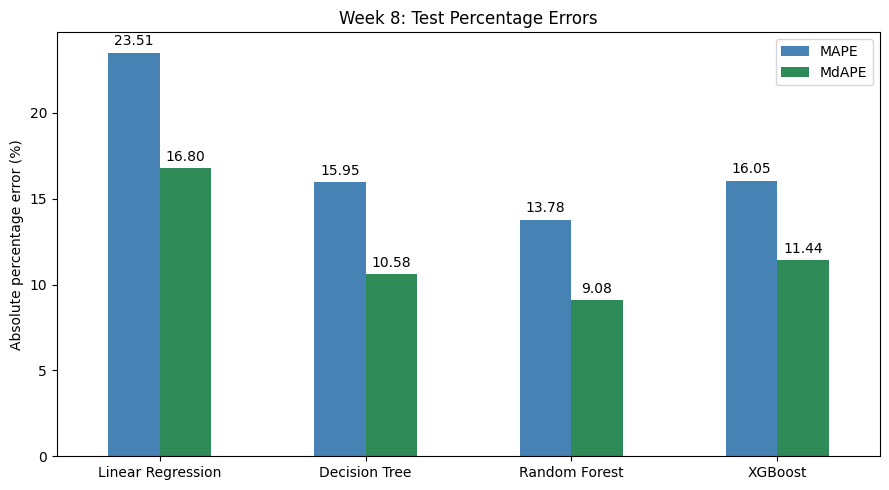

In [21]:
ax = metrics_summary.set_index("Model")[["MAPE_percent", "MdAPE_percent"]].plot.bar(
    figsize=(9, 5), color=["steelblue", "seagreen"]
)
ax.set_title("Week 8: Test Percentage Errors")
ax.set_ylabel("Absolute percentage error (%)")
ax.set_xlabel("")
ax.legend(["MAPE", "MdAPE"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Compare actual price bands
Group properties using actual sale prices, then compare each model within those same groups.
These fixed dollar bands are descriptive choices, not tuned parameters.

Lower boundaries are included and upper boundaries are excluded: a $500,000
property belongs in the $500k–<$1M band. Report the number of properties because
results for small groups can be less stable. Empty bands are skipped.

In [22]:
price_labels = ["Under $500k", "$500k–<$1M", "$1M–<$2M", "$2M–<$5M", "$5M+"]
predictions["PriceBand"] = pd.cut(
    actual_prices,
    bins=[0, 500_000, 1_000_000, 2_000_000, 5_000_000, np.inf],
    labels=price_labels,
    right=False
)

band_results = []
for band in price_labels:
    in_band = predictions["PriceBand"].eq(band)
    if not in_band.any():
        continue
    for model in model_columns:
        errors = percentage_errors.loc[in_band, model]
        band_results.append({
            "PriceBand": band,
            "Model": model,
            "Properties": int(in_band.sum()),
            "MAPE_percent": errors.mean(),
            "MdAPE_percent": errors.median()
        })

price_band_metrics = pd.DataFrame(band_results)
display(price_band_metrics.round(2))

,PriceBand,Model,Properties,MAPE_percent,MdAPE_percent
0,Under $500k,Linear Regression,1688,43.57,34.18
1,Under $500k,Decision Tree,1688,18.89,10.13
2,Under $500k,Random Forest,1688,18.11,9.35
3,Under $500k,XGBoost,1688,24.40,15.69
4,$500k–<$1M,Linear Regression,5131,23.90,18.49
5,$500k–<$1M,Decision Tree,5131,12.98,8.29
6,$500k–<$1M,Random Forest,5131,11.46,7.32
7,$500k–<$1M,XGBoost,5131,14.34,9.99
8,$1M–<$2M,Linear Regression,3772,16.53,12.39
9,$1M–<$2M,Decision Tree,3772,16.38,12.02


## 7. View the price-band comparison side by side

The compact table compares median percentage error for all four models. Keep
the bands in price order and show their sample counts alongside the results.
The lowest value in a row identifies the best MdAPE for that price band.

In [23]:
band_mdape = price_band_metrics.pivot(
    index="PriceBand", columns="Model", values="MdAPE_percent"
).reindex(index=price_labels, columns=model_columns).dropna(how="all")

band_counts = predictions["PriceBand"].value_counts().reindex(band_mdape.index)
band_comparison = band_mdape.copy()
band_comparison.insert(0, "Properties", band_counts)
display(band_comparison.round(2))

Model,Properties,Linear Regression,Decision Tree,Random Forest,XGBoost
PriceBand,,,,,
Under $500k,1688,34.18,10.13,9.35,15.69
$500k–<$1M,5131,18.49,8.29,7.32,9.99
$1M–<$2M,3772,12.39,12.02,10.08,11.08
$2M–<$5M,1524,13.43,16.50,12.99,13.41
$5M+,164,30.79,24.54,23.24,21.54


## 8. Save the evaluation results

`metrics_summary.csv` is the required Week 8 CSV deliverable. The additional
price-band CSV preserves the breakdown used to write the findings.

In [25]:
metrics_summary.to_csv("../data/processed/metrics_summary.csv", index=False)
price_band_metrics.to_csv("../data/processed/price_band_metrics.csv", index=False)
print("Saved metrics_summary.csv and price_band_metrics.csv.")

Saved metrics_summary.csv and price_band_metrics.csv.


## 9. Summary and findings

This week, we evaluated all four models on **12,279 properties** from **2026-04**, adding MAPE, MdAPE, and MAE alongside R². **Random Forest** had the lowest MdAPE at **9.08%**, with MAPE of **13.78%** and MAE of **\$181,306**. **XGBoost** had the highest test R² at **0.8717**. For the lowest-MdAPE model, median percentage error was lowest in **\$500k–<\$1M** (**7.32%**, 5131 properties) and highest in **\$5M+** (**23.24%**, 164 properties). These comparisons show how performance differs across metrics and price ranges.